In [1]:
import tensorflow_probability.substrates.jax as tfp
from jax import config
config.update("jax_enable_x64", True)
from jax import random, numpy as jnp

from jaxns import DefaultNestedSampler
from jaxns import Model
from jaxns import Prior
from jaxns import summary, plot_diagnostics, plot_cornerplot, save_results, load_results, save_pytree

tfpd = tfp.distributions

from jax._src.scipy.linalg import solve_triangular
from petitRADTRANS.radtrans import Radtrans
import petitRADTRANS.physical_constants as cst
from petitRADTRANS.retrieval.jax_parameter import Parameter
from petitRADTRANS.retrieval.jax_rebin import rebin_spectrum

import copy as cp
import matplotlib.pyplot as plt




INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/nasedkin/anaconda3/envs/prt3python312/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file), '/usr/local/lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache)


In [2]:

def _compute_gravity(parameters):
    gravity = 10 ** parameters['log_g'].value
    planet_radius = parameters['planet_radius'].value
    
    return gravity, planet_radius
def flux2irradiance(flux, source_radius, target_distance):
    """Calculate the spectral irradiance of a spherical source on a target from its flux (spectral radiosity).

    Args:
        flux: (M.L-1.T-3) flux of the source
        source_radius: (L) radius of the spherical source
        target_distance: (L) distance from the source to the target

    Returns:
        The irradiance of the source on the target (M.L-1.T-3).
    """
    return flux * (source_radius / target_distance) ** 2
def temperature_profile_function_guillot(pressures, infrared_mean_opacity, gamma, gravities, intrinsic_temperature,
                                         equilibrium_temperature, redistribution_coefficient=0.25):
    """ Returns a temperature array, in units of K,
    of the same dimensions as the pressure P
    (in bar).

    For this the temperature model of Guillot (2010) is used (his Equation 29).
    Source: https://doi.org/10.1051/0004-6361/200913396

    Args:
        pressures:
            numpy array of floats, containing the input pressure in bars.
        infrared_mean_opacity:
            The infrared mean opacity in units of :math:`\\rm cm^2/s`.
        gamma:
            The ratio between the visual and infrared mean opacities.
        gravities:
            The planetary gravity at the given pressures in units of :math:`\\rm cm/s^2`.
        intrinsic_temperature:
            The planetary intrinsic temperature (in units of K).
        equilibrium_temperature:
            The planetary equilibrium temperature (in units of K).
        redistribution_coefficient:
            The redistribution coefficient of the irradiance. A value of 1 corresponds to the substellar point, 1/2 for
            the day-side average and 1/4 for the global average.
    """
    # Estimate tau from eq. 24: m is the column mass, dm = rho * dz, dP / dz = -g * rho, so m = P / g
    tau = infrared_mean_opacity * pressures * 1e6 / gravities
    t_irr = equilibrium_temperature * 2.0 ** 0.5  # from eqs. 1 and 2

    temperature = (
                          0.75 * intrinsic_temperature ** 4. * (2. / 3. + tau)
                          + 0.75 * t_irr ** 4. * redistribution_coefficient
                          * (
                                  2. / 3.
                                  + 1. / gamma / 3. ** 0.5
                                  + (gamma / 3. ** 0.5 - 1. / 3. ** 0.5 / gamma) * jnp.exp(-gamma * tau * 3. ** 0.5)
                          )
                  ) ** 0.25

    return temperature
def setup_clouds(pressures, parameters, cloud_species):
    """
    This function provides the set of cloud parameters used in
    petitRADTRANS. This will be some combination of atmospheric
    parameters (fsed and Kzz), distribution descriptions (log normal or hansen)
    and the cloud particle radius. Fsed and the particle radii can be provided
    on a per-cloud basis.

    Args:
        pressures : np.ndarray
            The pressure array used to provide the atmospheric grid
        parameters : dict
            The dictionary of parameters passed to the model function. Should contain:
                 *  fsed : sedimentation parameter - can be unique to each cloud type
                One of:
                  *  sigma_lnorm : Width of cloud particle size distribution (log normal)
                  *  b_hans : Width of cloud particle size distribution (hansen)
                One of:
                  *  log_cloud_radius_* : Central particle radius (typically computed with fsed and Kzz)
                  *  log_kzz : Vertical mixing parameter
        cloud_species : list
            A list of the names of each of the cloud species used in the atmosphere.

    Returns:
        sigma_lnorm : float, None
            The width of a log normal particle size distribution
        fseds : dict, None
            The sedimentation fraction for each cloud species in the atmosphere
        kzz : np.ndarray, None
            The vertical mixing parameter
        b_hans : float, None
            The width of a hansen particle size distribution
        radii : dict, None
            The central radius of the particle size distribution
        distribution : string
            Either "lognormal" or "hansen" - tells pRT which distribution to use.
    """
    sigma_lnorm = None
    b_hans = None
    distribution = "lognormal"
    kzz = None

    # Setup distribution shape
    if "sigma_lnorm" in parameters.keys():
        sigma_lnorm = parameters['sigma_lnorm'].value

    # Are we retrieving the particle radii?
    radii = {}

    for cloud in cloud_species:
        if 'log_cloud_radius_' + cloud.split('_')[0] in parameters.keys():
            radii[cloud] = 10 ** parameters['log_cloud_radius_' + cloud.split('_')[0]].value * jnp.ones_like(pressures)
    if not radii:
        radii = None

    # per-cloud species fseds
    fseds = get_fseds(parameters, cloud_species)
    if "log_kzz" in parameters.keys():
        kzz = 10 ** parameters["log_kzz"].value * jnp.ones_like(pressures)
    return sigma_lnorm, fseds, kzz, b_hans, radii, distribution

def cloud_dict(parameters, parameter_name, cloud_species, shape=0):
    """
    This is a generic method to create a dictionary of
    parameters values for a given cloud parameterization, testing if
    the parameter should be filled on a per-species basis or
    if each cloud species should have the same value.
    """
    output_dictionary = {}

    for cloud in cloud_species:
        cname = cloud.split('_')[0]
        output = None

        if parameter_name + "_" + cname in parameters.keys():
            output = parameters[parameter_name + "_" + cname].value
        elif parameter_name in parameters.keys():
            output = parameters[parameter_name].value

        if shape > 0:
            output = output * jnp.ones(shape)

        output_dictionary[cloud] = output

    if not output_dictionary:
        output_dictionary = None

    return output_dictionary


def get_fseds(parameters, cloud_species):
    """
    This function checks to see if the fsed values are input on a per-cloud basis
    or only as a single value, and returns the dictionary providing the fsed values
    for each cloud, or None, if no cloud is used.
    """
    return cloud_dict(parameters, "fsed", cloud_species)

import sys
from petitRADTRANS._input_data_loader import get_species_isotopologue_name, split_species_all_info
from petitRADTRANS.physical_constants import e_molar_mass
from molmass import Formula
def compute_mean_molar_masses(abundances):
    """Calculate the mean molecular weight in each layer.

    Args:
        abundances : dict
            dictionary of abundance arrays, each array must have the shape of the pressure array used in pRT,
            and contain the abundance at each layer in the atmosphere.
    """
    mean_molar_masses = (sys.float_info.min
                         * jnp.ones_like(abundances[list(abundances.keys())[0]]))  # prevent division by 0

    for key in abundances.keys():
        if '(s)' in key or '(l)' in key:  # ignore clouds
            continue

        # exo_k resolution
        spec = key.split(".R")[0]
        mean_molar_masses += abundances[key] / get_species_molar_mass(spec)

    return 1.0 / mean_molar_masses

def get_molmass_name(species):
    species = get_species_isotopologue_name(species, join=True)

    name, natural_abundance, charge, _, _, _ = split_species_all_info(species)

    # Rearrange isotopes in molmass format
    isotopes = name.split('-')

    if natural_abundance != '':
        return [''.join(isotopes) + charge]

    isotopes.append(charge)

    return isotopes

def get_species_molar_mass(species):
    """
    Get the molecular mass of a given species.

    This function uses the molmass package to calculate the mass number for the standard isotope of an input species.
    If all_iso is part of the input, it will return the mean molar mass.

    Args:
        species : string
            The chemical formula of the compound. ie C2H2 or H2O
    Returns:
        The molar mass of the compound in atomic mass units.
    """
    if species == 'e-':
        return e_molar_mass

    if "-NatAbund" in species:
        natural_abundance = True
    else:
        natural_abundance = False

    names = get_molmass_name(species)

    molar_mass = None

    if natural_abundance and len(names) == 1:
        return Formula(names[0]).mass
    elif natural_abundance and len(names) != 1:
        raise ValueError(f"species '{species}' has the natural abundance flag, "
                         f"but several isotopes were detected: ({names})")
    elif not natural_abundance:
        molar_mass = 0.0
        charge = None

        # molmass cannot manage formulae containing both '[]'-separated isotopes and charges,
        if names[-1] == '':
            charge = 0.0
        elif names[-1][-1] in ['+', '-']:
            charge = names[-1].replace('_', '')  # get rid of the leading '_'
            charge = charge[-1] + charge[:-1]  # put sign in front of digits

            if len(charge) == 1:
                charge = charge + '1'  # when no charge number is given, assume that it is 1

            charge = float(charge)

        for name in names[:-1]:
            molar_mass += Formula(name).isotope.massnumber

        # Change charge sign ('+' means *less* e-, thanks B. Franklin! https://xkcd.com/567/)
        molar_mass += -charge * e_molar_mass

    return molar_mass

def jax_guillot_emission(prt_object,
                     parameters,
                     pt_plot_mode=False,
                     amr=False):
    """
    Emission spectrum calculation for the Guillot 2010 temperature profile.
    (Dis)equilibrium or free chemistry, can be used. The use of easychem for on-the-fly (dis)equilibrium
    chemistry calculations is supported, but is currently under development.

    Args:
        prt_object : object
            An instance of the pRT class, with optical properties as defined in the RunDefinition.
        parameters : dict
            Dictionary of required parameters:
                *  D_pl : Distance to the planet in [cm]
                Two of
                  *  log_g : Log of surface gravity
                  *  planet_radius : planet radius [cm]
                  *  mass : planet mass [g]
                *  T_int : Interior temperature of the planet [K]
                *  T_equ : Equilibrium temperature of the planet
                *  gamma : Guillot gamma parameter
                *  log_kappa_IR : The log of the ratio between the infrared and optical opacities

                Either:
                  *  log_pquench : Pressure at which CO, CH4 and H2O abundances become vertically constant
                  *  Fe/H : Metallicity
                  *  C/O : Carbon to oxygen ratio
                Or:
                  * $SPECIESNAME[_$DATABASE][_R_$RESOLUTION] : The log mass fraction abundance of the species

                *  fsed : sedimentation parameter - can be unique to each cloud type
                One of:
                  *  sigma_lnorm : Width of cloud particle size distribution (log normal)
                  *  b_hans : Width of cloud particle size distribution (hansen)
                One of:
                  *  log_cloud_radius_* : Central particle radius (typically computed with fsed and Kzz)
                  *  log_kzz : Vertical mixing parameter
                One of
                  *  eq_scaling_* : Scaling factor for equilibrium cloud abundances.
                  *  log_X_cb_: cloud mass fraction abundance
                Optional
                  *  contribution : return the emission contribution function
        pt_plot_mode : bool
        pt_plot_mode : bool
            Return only the pressure-temperature profile for plotting. Evaluate mode only.
        amr :
            Adaptive mesh refinement. Use the high resolution pressure grid around the cloud base.

    Returns:
        wlen_model : np.array
            Wavlength array of computed model, not binned to data [um]
        spectrum_model : np.array
            Computed transmission spectrum planet_radius**2/Rstar**2
        contr-em : np.ndarray
            Optional, Emission contribution function, relative contributions for each wavelength and pressure level.

    """
    p_use = prt_object.pressures / 1e6

    contribution = False
    if "contribution" in parameters.keys():
        contribution = parameters["contribution"].value
    gravity, planet_radius = _compute_gravity(parameters)

    temperatures = temperature_profile_function_guillot(
        p_use,
        10 ** parameters['log_kappa_IR'].value,
        10 ** parameters['log_gamma'].value,
        gravity,
        parameters['T_int'].value,
        parameters['T_equ'].value
    )

    # If in evaluation mode, and PTs are supposed to be plotted
    # Free chemistry species
    abundances = {}
    msum = 0.0
    for species in prt_object.line_species:
        if species.split(".R")[0] in parameters.keys():
            abund = 10 ** parameters[species.split(".R")[0]].value
            abundances[species] = abund * jnp.ones_like(p_use)
            msum += abund
    abundances['H2'] = 0.766 * (1.0 - msum) * jnp.ones_like(p_use)
    abundances['He'] = 0.234 * (1.0 - msum) * jnp.ones_like(p_use)
    mmw = compute_mean_molar_masses(abundances)

    pressures = p_use

    sigma_lnorm, fseds, kzz, b_hans, radii, distribution = setup_clouds(pressures, parameters,
                                                                        prt_object.cloud_species)
    wlen_model, flux, additional_outputs = prt_object.calculate_flux(
        temperatures=temperatures,
        mass_fractions=abundances,
        reference_gravity=gravity,
        mean_molar_masses=mmw,
        return_contribution=contribution,
        cloud_f_sed=fseds,
        eddy_diffusion_coefficients=kzz,
        cloud_particle_radius_distribution_std=sigma_lnorm,
        cloud_hansen_b=b_hans,
        cloud_particles_mean_radii=radii,
        cloud_particles_radius_distribution=distribution
    )

    # Getting the model into correct units
    wlen_model *= 1e4  # cm to um
    f_lambda = flux * 1e-7  # erg.s-1.cm-2/cm to W.m-2/um

    spectrum_model = flux2irradiance(
        f_lambda,
        planet_radius,
        parameters['D_pl'].value
    )
    if contribution:
        return wlen_model, spectrum_model, additional_outputs['emission_contribution']
    return wlen_model, spectrum_model

<ErrorbarContainer object of 3 artists>

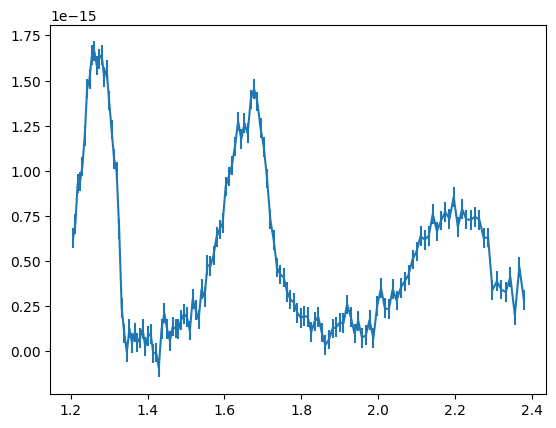

In [3]:

data_file = "TestDataGuillotBinnedNoisy.npy"
data = jnp.load(f"/Users/nasedkin/Documents/TCD/{data_file}").T
covariance = jnp.diag(data[2]**2)
inverse_covariance = jnp.linalg.inv(covariance)


fig,ax = plt.subplots()
ax.errorbar(data[0],data[1],yerr = data[2])

In [4]:
species = ['H2O__POKAZATEL.R300', 'CO-NatAbund__HITEMP.R300']

rayleigh_species = ['H2', 'He']
continuum_opacities = ['H2-H2', 'H2-He']
#cloud_species = ["Fe(c)_cd","MgSiO3(c)_cd"]
cloud_species = []
pressures = jnp.logspace(-6,3,100)

atmosphere = Radtrans(pressures=pressures,
                      line_species = cp.copy(species),
                      rayleigh_species = cp.copy(rayleigh_species),
                      gas_continuum_contributors = cp.copy(continuum_opacities),
                      cloud_species = cp.copy(cloud_species),
                      line_opacity_mode='c-k',
                      wavelength_boundaries = [1.0,2.5],
                      scattering_in_emission = False)


global_parameters = {}
global_parameters['D_pl'] = Parameter('D_pl', False, value = 10.0*cst.pc)
global_parameters['pressure_simple'] = Parameter('pressure_simple', False, value = 100)
global_parameters['pressure_scaling'] = Parameter('pressure_scaling', False, value = 10)
global_parameters['pressure_width'] = Parameter('pressure_width', False, value = 3)

global_parameters["planet_radius"] = Parameter(name = "planet_radius",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=0.8*cst.r_jup, high= 2.0*cst.r_jup))
global_parameters["log_g"] = Parameter(name = "log_g",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=3.5, high= 5.0))
global_parameters["T_int"] = Parameter(name = "T_int",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=100.0, high= 2000.0))
global_parameters["T_equ"] = Parameter(name = "T_equ",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=100.0, high= 2000.0))
global_parameters["log_gamma"] = Parameter(name = "log_gamma",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=-3, high= 1))
global_parameters["log_kappa_IR"] = Parameter(name = "log_kappa_IR",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=-4, high= 2))
global_parameters["H2O__POKAZATEL"] = Parameter(name = "H2O__POKAZATEL",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=-4, high= -0.5))
global_parameters["CO-NatAbund__HITEMP"] = Parameter(name = "CO-NatAbund__HITEMP",
                                               is_free_parameter = True,
                                               distribution = tfpd.Uniform(low=-4, high= -0.5))

/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/_input_data_loader.py:275: UserWarning: file '.DS_Store' lack spectral information (resolution: , range: )
  warnings.warn(f"file '{file}' lack spectral information "


File '/Users/nasedkin/testing/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R300_0.3-50mu.ktable.petitRADTRANS.h5' already exists, skipping re-binning...
Loading Radtrans opacities...
File '/Users/nasedkin/testing/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R300_0.3-50mu.ktable.petitRADTRANS.h5' already exists, skipping re-binning...


/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/_input_data_loader.py:275: UserWarning: file '.DS_Store' lack spectral information (resolution: , range: )
  warnings.warn(f"file '{file}' lack spectral information "


 Loading line opacities of species 'H2O__POKAZATEL.R300' from file '/Users/nasedkin/testing/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
File '/Users/nasedkin/testing/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R300_0.1-250mu.ktable.petitRADTRANS.h5' already exists, skipping re-binning...
 Loading line opacities of species 'CO-NatAbund__HITEMP.R300' from file '/Users/nasedkin/testing/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R300_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Successfully loaded all line opacities
 Loading CIA opacities for H2-H2 from file '/Users/nasedkin/testing/input_data/opacities/continuum/collision_induced_absorptions/H2--H2/H2--H2-NatAbund/H2--H2-NatAbund__BoRi.R831_0.6-250mu.ciatable.petitRADTRANS.h5'... Done.
 Loading CIA opacities for H2-He from file '/Users/nasedkin/testing/input_data/opacities/continuum/collision_induce

In [5]:
parameters = {}
parameters['log_g'] = Parameter('log_g', False, value = 4.00)
parameters['D_pl'] = Parameter('D_pl', False, value = 20.0*cst.pc)
parameters['planet_radius'] = Parameter('planet_radius', False, value = 1.0*cst.r_jup)
parameters['T_int'] = Parameter('T_int', False, value = 500)
parameters['T_equ'] = Parameter('T_equ', False, value = 100)
parameters['log_gamma'] = Parameter('log_gamma', False, value = -1)
parameters['log_kappa_IR'] = Parameter('log_kappa_IR', False, value = 0.1)

parameters['H2O__POKAZATEL'] = Parameter('H2O__POKAZATEL', False, value = -1.5)
parameters['CO-NatAbund__HITEMP'] = Parameter('CO_all_iso_HITEMP', False, value = -1.3)

parameters['pressure_simple'] = Parameter('pressure_simple', False, value = 100)
parameters['pressure_scaling'] = Parameter('pressure_scaling', False, value = 10)
parameters['pressure_width'] = Parameter('pressure_width', False, value = 3)



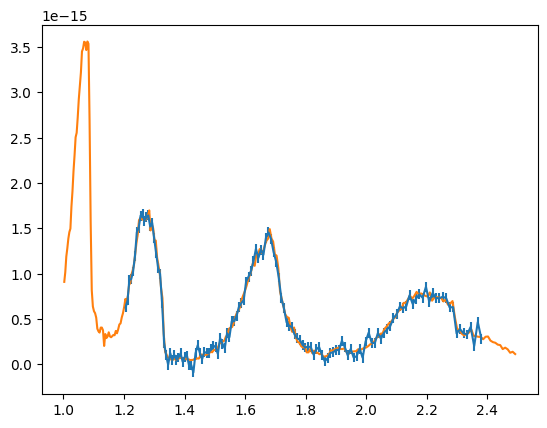

In [6]:
wlen, spectrum = jax_guillot_emission(atmosphere, parameters, False,False)
fig,ax = plt.subplots()
ax.errorbar(data[0],data[1],yerr = data[2])
ax.plot(wlen,spectrum)

In [7]:
%timeit jax_guillot_emission(atmosphere, parameters, False,False)


59.9 ms ± 372 µs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [8]:
%prun jax_guillot_emission(atmosphere, parameters, False,False)


         20817 function calls (20768 primitive calls) in 0.075 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.010    0.010    0.017    0.017 radtrans.py:637(_calculate_flux)
       53    0.009    0.000    0.010    0.000 dispatch.py:79(apply_primitive)
        1    0.008    0.008    0.008    0.008 radtrans.py:1167(_compute_ck_flux)
        2    0.006    0.003    0.024    0.012 radtrans.py:2365(_interpolate_cia)
        1    0.005    0.005    0.011    0.011 radtrans.py:2401(_interpolate_species_opacities)
       72    0.004    0.000    0.004    0.000 array_methods.py:260(deferring_binary_op)
        4    0.003    0.001    0.003    0.001 pjit.py:1503(_pjit_call_impl)
        1    0.002    0.002    0.007    0.007 radtrans.py:1122(_combine_opacities)
        1    0.002    0.002    0.026    0.026 radtrans.py:1131(_compute_cia_opacities)
        1    0.002    0.002    0.050    0.050 radtrans.py:749(_calculate_opaci

In [9]:
def prior_model():
    #print("PRIORS")
    for key,parameter in global_parameters.items():
        if not parameter.is_free_parameter:
            continue
        parameter.set_prior()
        parameter.value = yield parameter.prior_sample
        #print(key,parameter.value)
    return global_parameters

def log_likelihood(parameters):
    #print("LIKELIHOOD PARAMS")
    #for key, value in parameters.items():
    #    print(key,value.value)
    wavelength, model_spectrum = jax_guillot_emission(atmosphere, parameters, False, False)
    binned_model_spectrum = rebin_spectrum(wavelength, model_spectrum, data[0])

    diff = binned_model_spectrum - data[1]
    loglikelihood = -0.5*jnp.dot(diff.T,jnp.dot(inverse_covariance,diff))
    return loglikelihood

model = Model(prior_model=prior_model,
              log_likelihood=log_likelihood)




In [10]:
prior_model()
ll = log_likelihood(global_parameters)
print(ll)

-11752.005077482821


In [11]:
ns = DefaultNestedSampler(
    model=model,
    max_samples=1e7,
    num_live_points = 40,
    parameter_estimation = True,
    num_parallel_workers = 1,
    verbose=True)

termination_reason, state = ns(random.PRNGKey(42654))
results = ns.to_results(termination_reason=termination_reason, state=state)


INFO:jaxns:Number of parallel Markov-chains set to: 4


-------
Num samples: 40
Num likelihood evals: 17
Efficiency: 2.1176470588235294
log(L) contour: -377043.25216067163
log(Z) est.: -8467.641943359582 +- 0.8210442143065922
-------
Num samples: 76
Num likelihood evals: 90
Efficiency: 0.4
log(L) contour: -8464.109727260407
log(Z) est.: -655.7161154822247 +- 0.915096486676763
-------
Num samples: 112
Num likelihood evals: 331
Efficiency: 0.10876132930513595
log(L) contour: -3107.8378813955987
log(Z) est.: -656.690333676522 +- 1.0003447195887383
-------
Num samples: 148
Num likelihood evals: 747
Efficiency: 0.04819277108433735
log(L) contour: -1420.173369741026
log(Z) est.: -657.6645518708194 +- 1.0788779060163458
-------
Num samples: 184
Num likelihood evals: 1189
Efficiency: 0.030277544154751892
log(L) contour: -1029.3923587295667
log(Z) est.: -602.964422303135 +- 1.152070099503989
-------
Num samples: 220
Num likelihood evals: 1683
Efficiency: 0.0213903743315508
log(L) contour: -662.0128615613285
log(Z) est.: -603.9353443479328 +- 1.22034

In [12]:
summary(results)


--------
Termination Conditions:
Small remaining evidence
--------
likelihood evals: 30387
samples: 1984
phantom samples: 1760
likelihood evals / sample: 15.3
phantom fraction (%): 88.7%
--------
logZ=-186.1 +- 3.6
H=-47.07
ESS=2
--------
CO-NatAbund__HITEMP: mean +- std.dev. | 10%ile / 50%ile / 90%ile | MAP est. | max(L) est.
CO-NatAbund__HITEMP: -0.887 +- 0.055 | -0.965 / -0.867 / -0.822 | -0.849 | -0.849
--------
H2O__POKAZATEL: mean +- std.dev. | 10%ile / 50%ile / 90%ile | MAP est. | max(L) est.
H2O__POKAZATEL: -2.008 +- 0.022 | -2.037 / -2.012 / -1.977 | -2.019 | -2.019
--------
T_equ: mean +- std.dev. | 10%ile / 50%ile / 90%ile | MAP est. | max(L) est.
T_equ: 963.0 +- 12.0 | 949.0 / 965.0 / 976.0 | 961.0 | 961.0
--------
T_int: mean +- std.dev. | 10%ile / 50%ile / 90%ile | MAP est. | max(L) est.
T_int: 247.0 +- 41.0 | 198.0 / 253.0 / 315.0 | 270.0 | 270.0
--------
log_g: mean +- std.dev. | 10%ile / 50%ile / 90%ile | MAP est. | max(L) est.
log_g: 3.5083 +- 0.0062 | 3.5018 / 3.5067

/Users/nasedkin/anaconda3/envs/prt3python312/lib/python3.12/site-packages/jaxns/plotting.py:47: UserWarning: Found samples with zero likelihood evaluations.
  warnings.warn("Found samples with zero likelihood evaluations.")
/Users/nasedkin/anaconda3/envs/prt3python312/lib/python3.12/site-packages/jaxns/plotting.py:51: RuntimeWarning: divide by zero encountered in divide
  1. / num_likelihood_evaluations_per_sample


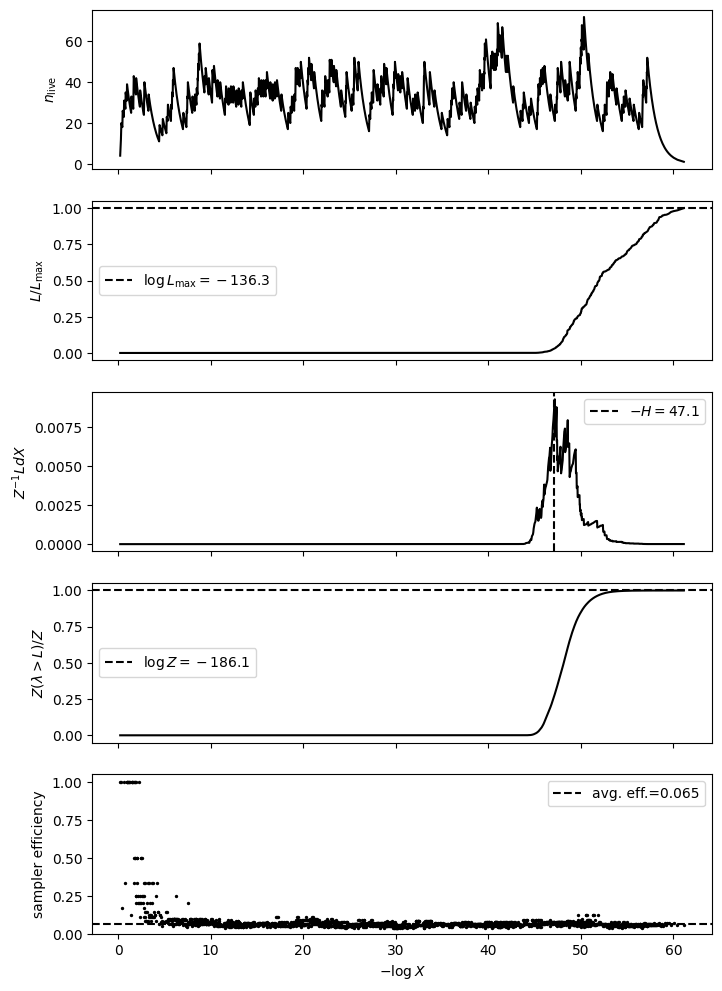

In [13]:
plot_diagnostics(results,"jax_testretrieval_diagnostics.pdf")


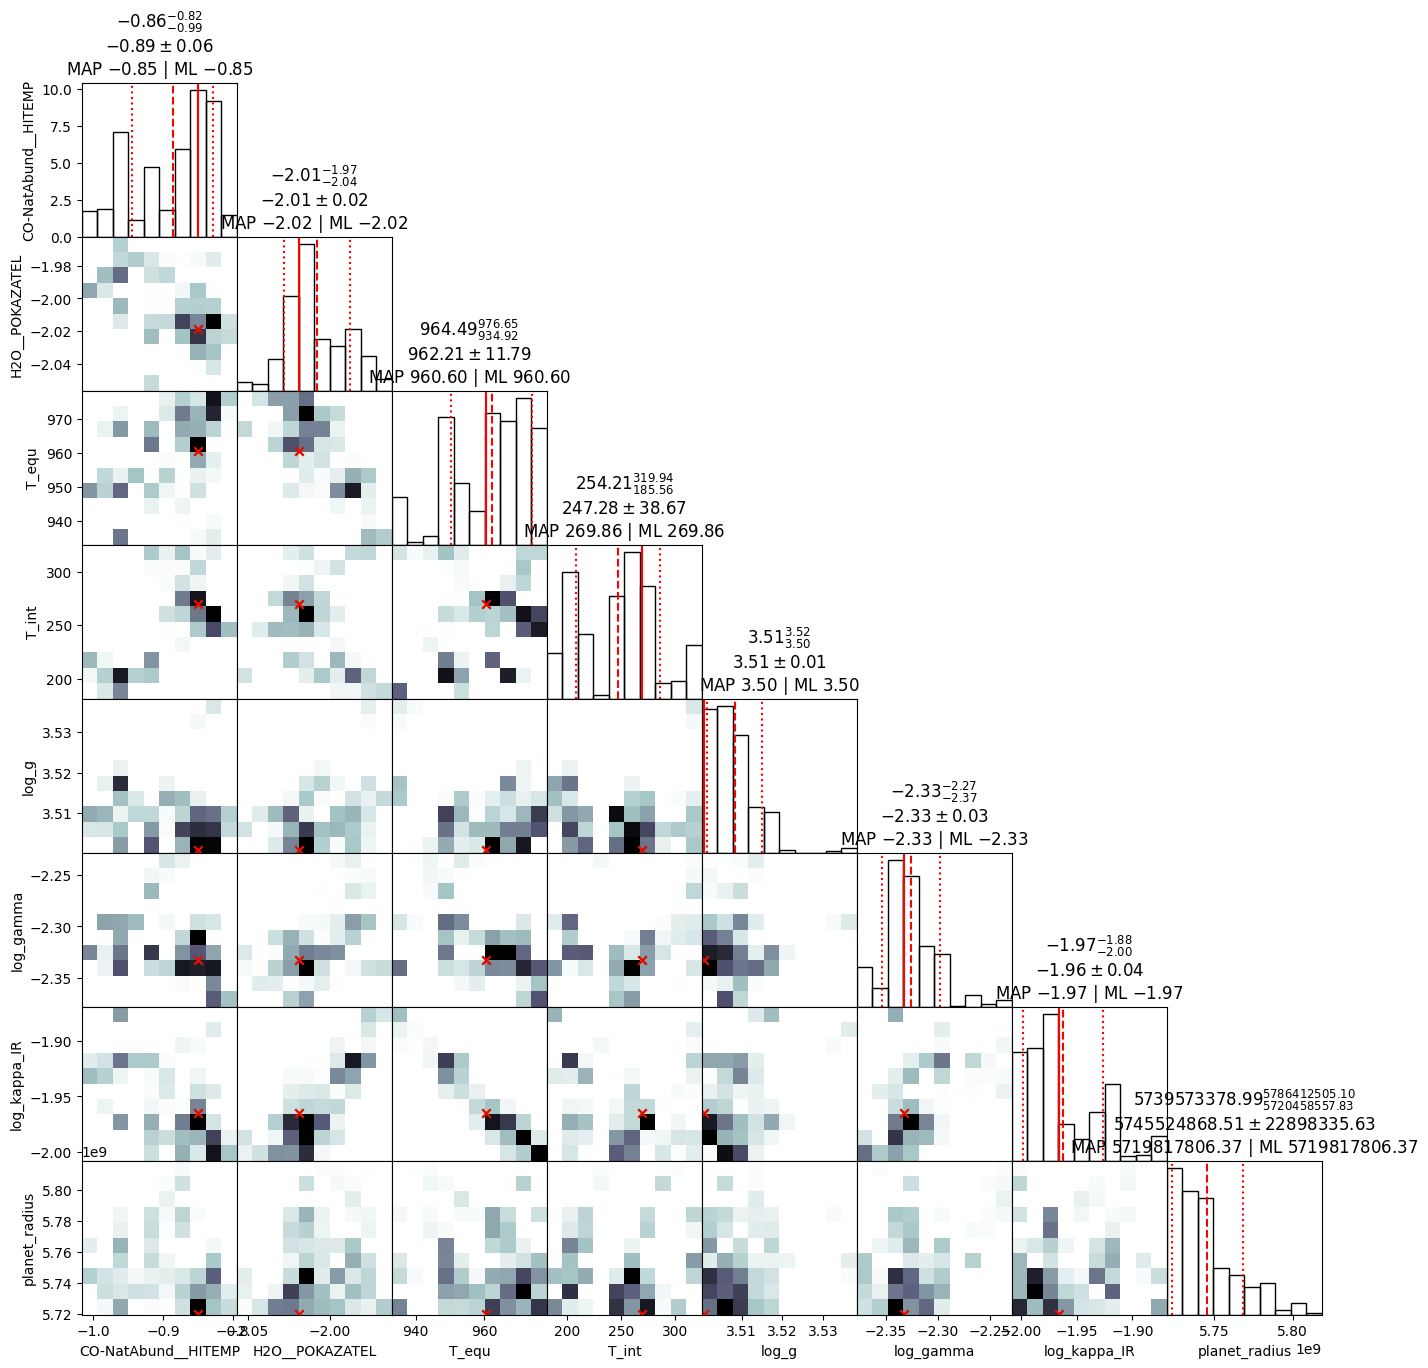

In [16]:
plot_cornerplot(results,save_name="jax_testretrieval_corner.pdf")

In [18]:
save_results(results,'jaxns_testretrieval_results.json')

TypeError: Object of type ArrayImpl is not JSON serializable

In [28]:
median_parameters = parameters
for key, value in median_parameters.items():
    if value.is_free_parameter:
        value.value = jnp.median(results.samples[key])


In [29]:
medwlen,medspec = jax_guillot_emission(atmosphere,median_parameters)

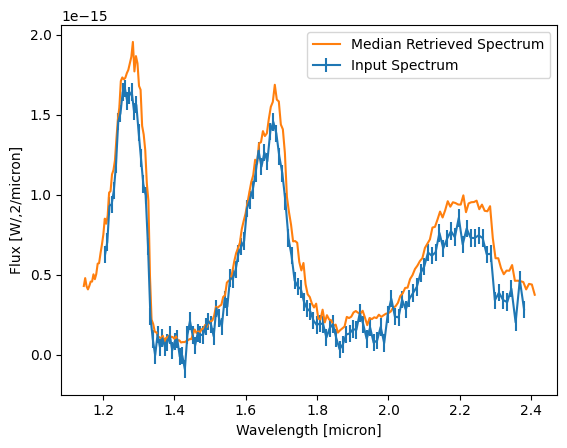

In [34]:
fig,ax = plt.subplots()
ax.errorbar(data[0],data[1],yerr = data[2], label = "Input Spectrum")
ax.plot(medwlen[40:-10],medspec[40:-10], label = "Median Retrieved Spectrum")
ax.set_xlabel("Wavelength [micron]")
ax.set_ylabel("Flux [W/,2/micron]")
ax.legend()
plt.savefig("jax_testretrieval_spectrum.pdf",bbox_inches='tight')